In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

In [3]:
# Generate a synthetic dataset with easy separability
X, y = make_classification(
    n_samples=1000,      # Total number of samples
    n_features=2,        # Number of features (dimensions)
    n_informative=2,     # Number of informative features
    n_redundant=0,       # Number of redundant features
    n_clusters_per_class=1,
    flip_y=0,            # Fraction of samples whose class is randomly exchanged
    class_sep=2,         # Separation between the classes
    random_state=42
)

In [4]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Convert data to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train)
X_test_tensor = torch.FloatTensor(X_test)
y_train_tensor = torch.LongTensor(y_train)
y_test_tensor = torch.LongTensor(y_test)

model = nn.Sequential(
    nn.Linear(2, 2),
    nn.ReLU(),
    nn.Linear(2, 2),
    nn.ReLU(),
    nn.Linear(2, 1),
#    nn.Sigmoid()
)
print(model)

In [25]:
# Define the neural network
class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()
        self.fc1 = nn.Linear(2, 10)
        self.fc2 = nn.Linear(10, 10)
        self.fc3 = nn.Linear(10, 2)
        # self.fc3 = nn.Sigmoid()

    
    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [26]:
# Initialize the network, define the criterion and optimizer
model = ANN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [27]:
# Train the network
num_epochs = 500
for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    optimizer.step()

    if (epoch+1) % 20 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [20/500], Loss: 2.2271
Epoch [40/500], Loss: 2.1767
Epoch [60/500], Loss: 2.1323
Epoch [80/500], Loss: 2.0935
Epoch [100/500], Loss: 2.0594
Epoch [120/500], Loss: 2.0299
Epoch [140/500], Loss: 2.0049
Epoch [160/500], Loss: 1.9836
Epoch [180/500], Loss: 1.9653
Epoch [200/500], Loss: 1.9499
Epoch [220/500], Loss: 1.9369
Epoch [240/500], Loss: 1.9258
Epoch [260/500], Loss: 1.9165
Epoch [280/500], Loss: 1.9087
Epoch [300/500], Loss: 1.9022
Epoch [320/500], Loss: 1.8969
Epoch [340/500], Loss: 1.8925
Epoch [360/500], Loss: 1.8889
Epoch [380/500], Loss: 1.8859
Epoch [400/500], Loss: 1.8834
Epoch [420/500], Loss: 1.8813
Epoch [440/500], Loss: 1.8796
Epoch [460/500], Loss: 1.8781
Epoch [480/500], Loss: 1.8769
Epoch [500/500], Loss: 1.8759


In [28]:
# Test the network
model.eval()
with torch.no_grad():
    train_outputs = model(X_train_tensor)
    test_outputs = model(X_test_tensor)
    _, y_pred_train = torch.max(train_outputs, 1)
    _, y_pred_test = torch.max(test_outputs, 1)

In [29]:
# Evaluate the model
train_accuracy = accuracy_score(y_train, y_pred_train.numpy())
test_accuracy = accuracy_score(y_test, y_pred_test.numpy())
classification_report_test = classification_report(y_test, y_pred_test.numpy())
conf_matrix = confusion_matrix(y_test, y_pred_test.numpy())

print(f"Training Accuracy: {train_accuracy:.2f}")
print(f"Testing Accuracy: {test_accuracy:.2f}")
print("Classification Report:\n", classification_report_test)

Training Accuracy: 1.00
Testing Accuracy: 1.00
Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      1.00       141
           1       1.00      0.99      1.00       159

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



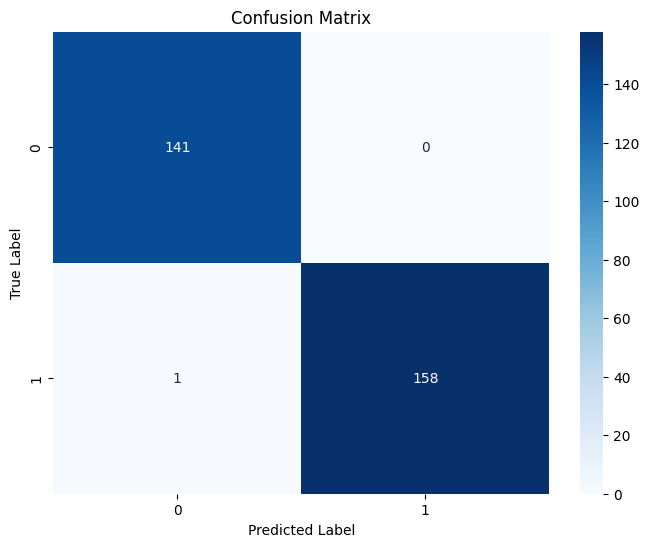

In [30]:
# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

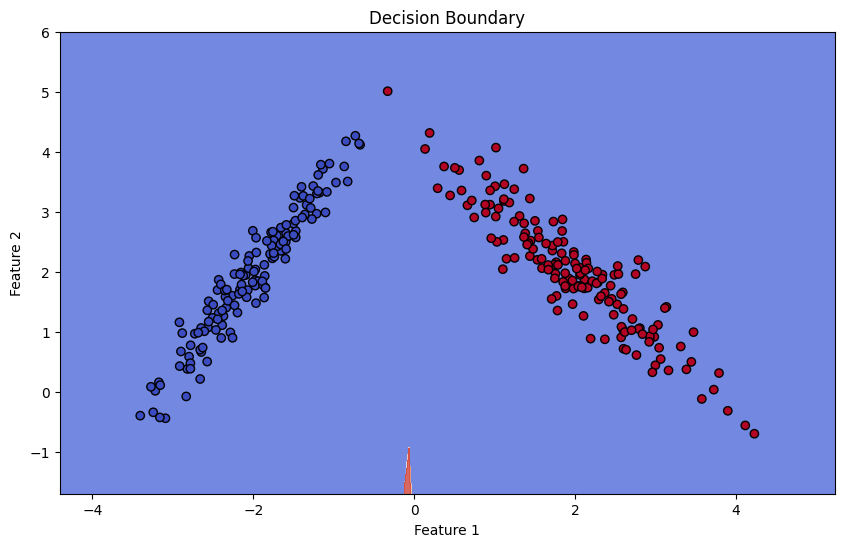

In [31]:
# Plot the decision boundary
def plot_decision_boundary(X, y, model):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                         np.arange(y_min, y_max, 0.01))
    X_grid = torch.FloatTensor(np.c_[xx.ravel(), yy.ravel()])
    with torch.no_grad():
        Z = model(X_grid)
        _, Z = torch.max(Z, 1)
        Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.8, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o', cmap='coolwarm')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title('Decision Boundary')

plt.figure(figsize=(10, 6))
plot_decision_boundary(X_test, y_test, model)
plt.show()